# Caso 1 · Pedido a fábrica — Análisis exploratorio

Entender demanda, inventario y restricciones antes de calcular el pedido, que se calcula en [`02_pedido_fabrica`](02_pedido_fabrica.ipynb). Parte de la base limpia de [`00_limpieza`](00_limpieza.ipynb).

| Dato | Valor |
|---|---|
| Periodo | Oct-2023 → Sep-2026 (36 meses) |
| Corte | 30-sep-2026 |
| Cierre de la ventana | 30-oct-2026 |
| Llegada del pedido | ~11-feb-2027 (lead time real de 104 días, §7) |
| Horizonte que cubre | mediados de feb → mediados de may de 2027 |

## 1. Supuestos
Decisiones que condicionan los resultados de este notebook y por qué se tomaron. En el texto y en el código se citan por su código.

| Código | Supuesto | Por qué | Dónde se aplica |
|---|---|---|---|
| **S1.2** | Las notas de crédito (`NC-…`) restan una unidad de la demanda, pero la unidad **no vuelve al inventario**. | Todas referencian una factura real del mismo modelo y versión, 4 a 24 días después: son devoluciones. La conciliación de inventario muestra que la hoja *Inventario* no devuelve la unidad al patio. | `00_limpieza` §4.2 |
| **S1.3** | Una línea de factura u oportunidad con 10 o más unidades (`FLEET_THRESHOLD = 10`) es flota especial y sale de la demanda base. | Las dos facturas (60 y 45 unidades) entraron por pedidos especiales fuera de ventana, como prevé el comunicado de fábrica; no salen del inventario normal. No hay líneas entre 5 y 44 unidades, así que el umbral exacto no cambia el resultado. | `00_limpieza` §4.3 |
| **S1.5** | Las combinaciones de inventario sin antigüedad se imputan con el promedio del modelo en ese mes (`age_days`). | Son 40 combinaciones y 104 unidades (<1 %); el promedio del modelo-mes es la mejor referencia disponible y no mueve los tramos de antigüedad. | `00_limpieza` §4.5 |
| **S1.6** | Las redacciones "sin disponibilidad / sin stock / sin inventario / versión o color no disponible" son un solo motivo de pérdida (`NO_AVAILABILITY_PATTERN`). | Describen la misma causa escrita en texto libre de ocho formas; separarlas subestimaría la demanda perdida por falta de stock. | `00_limpieza` §4.6 |
| **S1.7** | **Demanda ajustada** = venta neta de 12 meses (`DEMAND_WINDOW_MONTHS`) + leads perdidos por disponibilidad y sustituciones, **solo en los meses de quiebre** (el modelo empezó o terminó el mes en cero). | En los meses sin stock la venta registrada no mide la demanda: está censurada. Las pérdidas con el modelo en stock son de versión o color, así que corrigen la mezcla del pedido, no el volumen. | §6.2 |
| **S1.8** | El pedido llega con el lead time real (mediana 104 días) y un 12 % de las unidades llega ~1 mes tarde (`LEAD_TIME_DAYS`, `LATE_SHARE`, `LATE_DELAY_MONTHS`). El tránsito que llega antes del pedido suma a la posición, que se trunca en 0. | El lead time observado es estable en todos los trimestres y el "4 meses" del comunicado es conservador; la llegada tardía se repite cada trimestre y la ETA no la anticipa. La posición no puede ser negativa porque la venta perdida en el hueco no se recupera después. | `02_pedido_fabrica` §2 |

In [1]:
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve().parents[1]  # el notebook corre desde notebooks/caso1/
PROCESSED = ROOT / "data" / "processed" / "caso1_limpio.pkl"
assert PROCESSED.is_file(), f"No existe {PROCESSED}: ejecuta primero 00_limpieza.ipynb"
d = SimpleNamespace(**pd.read_pickle(PROCESSED))  # base limpia escrita por 00_limpieza.ipynb
CORTE = d.params["cutoff_date"]
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update(
    {
        "figure.figsize": (11, 4.5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 12,
        "legend.fontsize": 9,
    }
)
MODELOS = d.models  # catálogo oficial: los 11 modelos de la hoja "Economía por modelo"

# Ventanas de tiempo derivadas de la fecha de corte, para que el notebook sirva en cualquier ciclo
ULT_MES = CORTE.to_period("M")
MESES_12 = slice(str(ULT_MES - 11), str(ULT_MES))
MESES_6 = slice(str(ULT_MES - 5), str(ULT_MES))
MESES_3 = slice(str(ULT_MES - 2), str(ULT_MES))
PREV_12 = slice(str(ULT_MES - 23), str(ULT_MES - 12))


def monthly_table(df, model_col, value_col, models=None, months=None):
    # Pivote mes × modelo con ceros donde no hay registro (las hojas solo traen combinaciones con dato)
    t = df.pivot_table(index="month", columns=model_col, values=value_col, aggfunc="sum", fill_value=0)
    t = t.reindex(columns=models or MODELOS, fill_value=0)
    if months is None:
        months = pd.period_range(t.index.min(), t.index.max(), freq="M")
    return t.reindex(months, fill_value=0)


pd.Series(
    {
        k: len(v)
        for k, v in vars(d).items()
        if isinstance(v, pd.DataFrame) and k not in ("changes", "quality")
    },
    name="filas en la base limpia",
).to_frame()

,filas en la base limpia
sales,4665
base_sales,4663
inventory,4062
leads,12072
orders,2258
economics,11
communications,5
rules,11


## 2. Reglas de negocio (Comunicados)
Definen las restricciones del problema.

In [2]:
for _, r in d.communications.iterrows():
    display(Markdown(f"**{r['Fecha']:%Y-%m-%d} · {r['Emisor']}**  \n*{r['Asunto']}*  \n{r['Texto']}"))

**2024-02-12 · Toyota Motor Corporation - Oficina Regional Centroamérica y Caribe**  
*Calendario de pedidos y tiempos de entrega*  
Los pedidos de unidades para inventario se reciben en ventanas trimestrales (enero, abril, julio y octubre), con cierre el último día hábil del mes. El tiempo estándar desde la confirmación del pedido hasta la llegada al patio del distribuidor en Managua es de 4 meses (producción, embarque, tránsito marítimo y nacionalización). Ejemplo: un pedido confirmado en octubre llega en febrero. Pedidos especiales de flota se gestionan fuera de ventana.

**2025-06-03 · Toyota Motor Corporation - Oficina Regional Centroamérica y Caribe**  
*Lotes de producción y pedido mínimo por modelo*  
Para optimizar la asignación de producción y el llenado de contenedores, a partir de la ventana de julio 2025 cada pedido por modelo debe ser cero o cumplir el pedido mínimo, y la cantidad debe ser múltiplo del lote (mínimo / múltiplo): Hilux 12 / 6; Fortuner 8 / 4; Corolla 6 / 6; Corolla Cross 12 / 6; Yaris 16 / 8; Yaris Cross 12 / 6; RAV4 4 / 4; Land Cruiser Prado 2 / 2; Rush 8 / 4; Hiace 3 / 3; Raize 12 / 6. La mezcla de versiones y colores dentro de cada modelo es libre.

**2026-08-20 · Toyota Motor Corporation - Oficina Regional Centroamérica y Caribe**  
*Asignación de producción - ventana octubre 2026*  
Para la ventana de octubre 2026 la fábrica confirmará el 100% de las cantidades solicitadas en todos los modelos de la línea, dentro de las reglas de pedido mínimo y múltiplo vigentes.

**2026-09-15 · Toyota Motor Corporation - Oficina Regional Centroamérica y Caribe**  
*Lanzamiento de la nueva generación RAV4*  
La nueva generación de RAV4 (disponible en versiones híbrida e híbrida enchufable) inicia producción para la región en enero 2027. Las primeras unidades para Nicaragua podrán solicitarse en la ventana de enero 2027 y llegarían en mayo 2027 (lanzamiento comercial previsto: mayo 2027, en unos 7 meses). La ventana de octubre 2026 es la última en la que se puede solicitar la generación actual. Las unidades de la generación actual que no se vendan antes del lanzamiento no tienen apoyo de fábrica para su liquidación.

**2026-09-22 · Gerencia Comercial Toyota - Casa Pellas (ficticio)**  
*Instrucción para el pedido de la ventana de octubre 2026*  
Preparar la propuesta de pedido por modelo para la ventana que cierra el 30 de octubre de 2026. El costo financiero del inventario (plan piso) se mantiene en 0.9% mensual sobre el costo de la unidad. Política comercial vigente de descuento por antigüedad en patio: más de 180 días, 4% sobre precio; más de 270 días, 7%; más de 365 días, 10%.

In [3]:
# Pedido mínimo y múltiplo por modelo, parseados del comunicado del 2025-06-03 (leídos del texto del comunicado en 00_limpieza §4.7)
d.rules.rename(columns={"min_order": "Pedido mínimo", "lot_multiple": "Múltiplo"}).T

Modelo,Hilux,Fortuner,Corolla,Corolla Cross,Yaris,Yaris Cross,RAV4,Land Cruiser Prado,Rush,Hiace,Raize
Pedido mínimo,12,8,6,12,16,12,4,2,8,3,12
Múltiplo,6,4,6,6,8,6,4,2,4,3,6


**Restricciones para el pedido**
- Ventanas trimestrales. Lo pedido el 30-oct llega hacia el **11-feb-2027** y cubre hasta la llegada del pedido de enero (**~13-may**). Stock actual + tránsito deben aguantar **4.4 meses**.
- Por modelo: **0 o ≥ mínimo, en múltiplos del lote**. Versión y color son libres.
- Fábrica confirma el 100 % de lo pedido: no hay que inflar el pedido.
- **RAV4:** última ventana de la generación actual, sin apoyo para liquidar; la nueva (mayo 2027) es solo híbrida.
- **Sobrestock:** plan piso 0.9 % mensual más descuentos de 4 % (>180 días), 7 % (>270) y 10 % (>365).

## 3. Calidad de datos
Detalle en [`00_limpieza`](00_limpieza.ipynb): 15 tipos de problema tratados y las tres hojas operativas cuadran (inventario = anterior + recepciones − facturas). Según **S1.2**, la unidad de una nota de crédito resta demanda pero no vuelve al inventario.

In [4]:
d.quality.style.hide(axis="index")

Hoja,Problema,Filas,Tratamiento
Ventas,"Modelo con variantes (mayúsculas, espacios, prefijo 'Toyota')",87,Normalizado contra catálogo
Ventas,"Sucursal con variantes (MANAGUA CENTRAL, Mga Sur, Leon…)",13,Normalizado
Ventas,Filas duplicadas exactas,18,Eliminadas (S1.1)
Ventas,"Notas de crédito (devoluciones, −1 unidad)",9,Se netean de la demanda; no vuelven a inventario (S1.2)
Ventas,Facturas de flota especial (≥ 10 unidades),2,Excluidas de la demanda base (S1.3)
Ventas,Precio capturado en córdobas (~32-44x),13,Excluido del análisis de precio (S1.4)
Ventas,Color nulo,18,Se mantiene como desconocido
Inventario,Modelo con variantes,46,Normalizado
Inventario,Antigüedad nula,40,Imputada con el promedio del modelo-mes en age_days (S1.5)
Leads,Modelo de interés con variantes,164,Normalizado


## 4. Ventas
Demanda base = venta neta sin flotas especiales (**S1.3**: líneas de 10 o más unidades, que se piden aparte).

### 4.1 Tendencia general

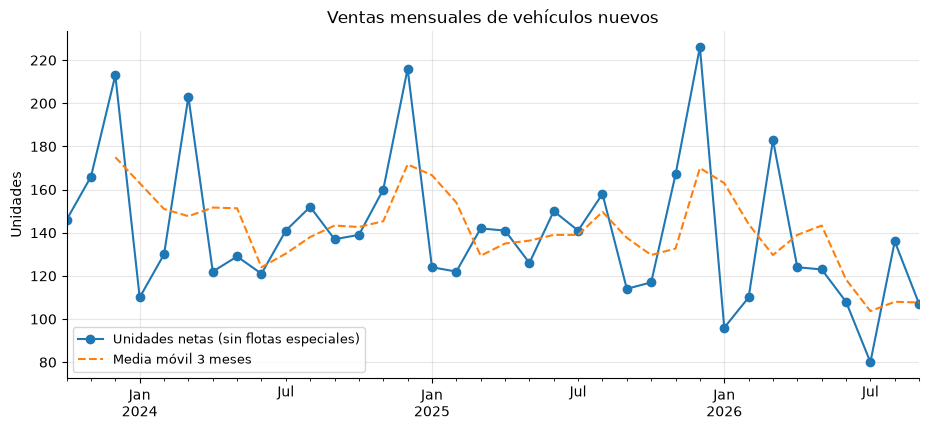

,Unidades,Variación
Oct2023-Sep2024,"1,770",—
Oct2024-Sep2025,"1,733",-2.1%
Oct2025-Sep2026,"1,577",-9.0%


In [5]:
base = d.base_sales
mensual = base.groupby("month")["Unidades"].sum()

fig, ax = plt.subplots()
mensual.plot(ax=ax, marker="o", label="Unidades netas (sin flotas especiales)")
mensual.rolling(3).mean().plot(ax=ax, ls="--", label="Media móvil 3 meses")
ax.set_title("Ventas mensuales de vehículos nuevos")
ax.set_xlabel("")
ax.set_ylabel("Unidades")
ax.legend()
plt.show()

anual = base.groupby("fiscal_year")["Unidades"].sum()
anual.index = [f"Oct{a - 1}-Sep{a}" for a in anual.index]
resumen_anual = pd.DataFrame({"Unidades": anual, "Variación": anual.pct_change()})
resumen_anual.style.format({"Unidades": "{:,.0f}", "Variación": "{:+.1%}"}, na_rep="—")

La venta anual cae −2 % y luego −9 %, pero parte de la caída coincide con quiebres de stock (§5).

### 4.2 Por modelo

In [6]:
por_modelo = monthly_table(base, "Modelo", "Unidades", MODELOS)
tot_modelo = por_modelo.sum().sort_values(ascending=False)
ult12, prev12 = por_modelo.loc[MESES_12].sum(), por_modelo.loc[PREV_12].sum()
ult6, ult3 = por_modelo.loc[MESES_6].sum(), por_modelo.loc[MESES_3].sum()

res_modelo = pd.DataFrame(
    {
        "Total 36m": tot_modelo,
        "Oct24-Sep25": prev12,
        "Oct25-Sep26": ult12,
        "Δ % año": ult12 / prev12 - 1,
        "Prom. mensual 12m": ult12 / 12,
        "Prom. mensual 6m": ult6 / 6,
        "Prom. mensual 3m": ult3 / 3,
        "Mix % (12m)": ult12 / ult12.sum(),
    }
).sort_values("Total 36m", ascending=False)
res_modelo.style.format(
    {
        "Δ % año": "{:+.1%}",
        "Mix % (12m)": "{:.1%}",
        "Prom. mensual 12m": "{:.1f}",
        "Prom. mensual 6m": "{:.1f}",
        "Prom. mensual 3m": "{:.1f}",
    }
).background_gradient(subset=["Δ % año"], cmap="RdYlGn", vmin=-0.6, vmax=0.6)

,Total 36m,Oct24-Sep25,Oct25-Sep26,Δ % año,Prom. mensual 12m,Prom. mensual 6m,Prom. mensual 3m,Mix % (12m)
Modelo,,,,,,,,
Hilux,1295,450,414,-8.0%,34.5,34.0,31.0,26.3%
Corolla Cross,799,291,213,-26.8%,17.8,8.7,8.0,13.5%
Yaris,545,175,169,-3.4%,14.1,13.8,12.0,10.7%
Yaris Cross,480,176,155,-11.9%,12.9,8.0,6.0,9.8%
Corolla,365,121,101,-16.5%,8.4,8.2,9.0,6.4%
Rush,346,129,88,-31.8%,7.3,3.3,2.7,5.6%
Fortuner,327,102,105,+2.9%,8.8,7.8,9.3,6.7%
Raize,313,101,104,+3.0%,8.7,9.7,8.0,6.6%
RAV4,275,81,113,+39.5%,9.4,10.0,12.7,7.2%


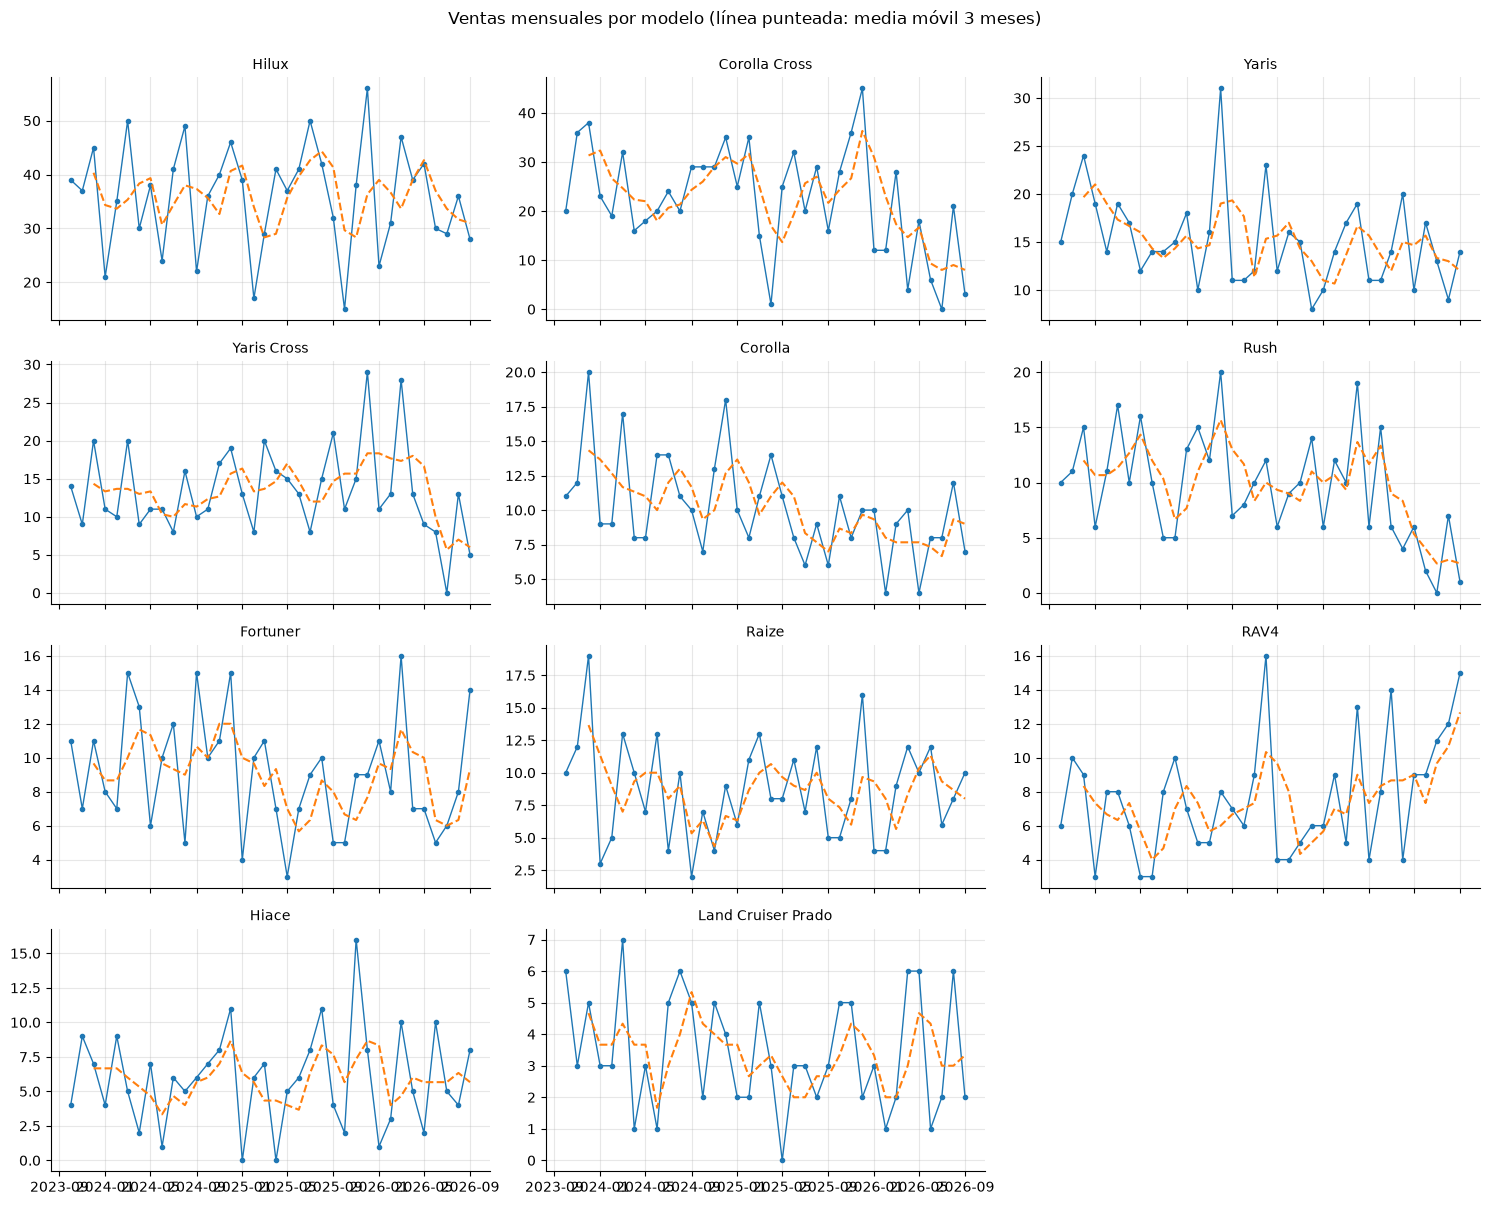

In [7]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12), sharex=True)
for ax, m in zip(axes.flat, tot_modelo.index, strict=False):
    s = por_modelo[m]
    ax.plot(s.index.to_timestamp(), s.values, marker=".", lw=1)
    ax.plot(s.index.to_timestamp(), s.rolling(3).mean().values, ls="--", lw=1.5)
    ax.set_title(m, fontsize=10)
axes.flat[-1].axis("off")
fig.suptitle("Ventas mensuales por modelo (línea punteada: media móvil 3 meses)", y=1.0)
plt.tight_layout()
plt.show()

- Hilux es ~1 de cada 4 unidades.
- **Corolla Cross, Yaris Cross y Rush** caen fuerte en el último semestre porque se quedaron sin stock: su venta subestima la demanda.
- El **+40 % de RAV4** es en parte prestado: 34 de sus 113 ventas fueron clientes de Corolla Cross (§6.3).

### 4.3 Estacionalidad
Índice = venta del mes ÷ promedio del año fiscal, por año.

,Oct2023-Sep2024,Oct2024-Sep2025,Oct2025-Sep2026,Promedio,Rango
Mes calendario,,,,,
1,0.750000,0.860000,0.730000,0.780000,0.130000
2,0.880000,0.840000,0.840000,0.850000,0.040000
3,1.380000,0.980000,1.390000,1.250000,0.410000
4,0.830000,0.980000,0.940000,0.920000,0.150000
5,0.870000,0.870000,0.940000,0.890000,0.060000
6,0.820000,1.040000,0.820000,0.890000,0.220000
7,0.960000,0.980000,0.610000,0.850000,0.370000
8,1.030000,1.090000,1.030000,1.050000,0.060000
9,0.930000,0.790000,0.810000,0.840000,0.140000


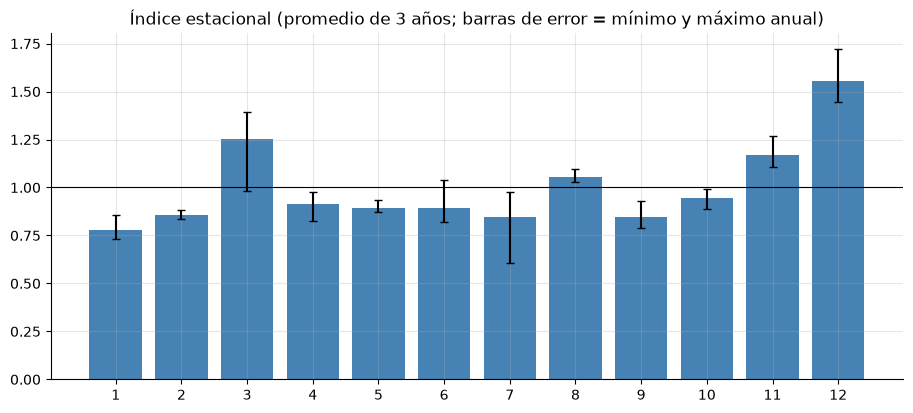

Horizonte del pedido (½ feb → ½ may): {2: 0.85, 3: 1.25, 4: 0.92, 5: 0.89} → factor ponderado 1.01
Hueco hasta que llegue (oct → ½ feb): {10: 0.95, 11: 1.17, 12: 1.55, 1: 0.78, 2: 0.85} → factor ponderado 1.08


In [8]:
t = mensual.to_frame("u")
t["fiscal_year"] = np.where(t.index.month >= 10, t.index.year + 1, t.index.year)
t["idx"] = t["u"] / t.groupby("fiscal_year")["u"].transform("mean")
estac_año = t.pivot_table(index=t.index.month, columns="fiscal_year", values="idx")
estac_año.index.name = "Mes calendario"
estac_año.columns = [f"Oct{a - 1}-Sep{a}" for a in estac_año.columns]
años = list(estac_año.columns)  # años fiscales presentes (no se asume que sean tres)
estac_año["Promedio"] = estac_año[años].mean(axis=1)
estac_año["Rango"] = estac_año[años].max(axis=1) - estac_año[años].min(axis=1)
display(estac_año.round(2).style.background_gradient(subset=["Promedio"], cmap="RdYlGn", vmin=0.6, vmax=1.5))

fig, ax = plt.subplots()
ax.bar(
    estac_año.index,
    estac_año["Promedio"],
    color="steelblue",
    yerr=[
        estac_año["Promedio"] - estac_año[años].min(axis=1),
        estac_año[años].max(axis=1) - estac_año["Promedio"],
    ],
    capsize=3,
)
ax.axhline(1, color="k", lw=0.8)
ax.set_xticks(range(1, 13))
ax.set_title(f"Índice estacional (promedio de {len(años)} años; barras de error = mínimo y máximo anual)")
plt.show()
# El pedido llega a mediados de febrero y se vende hasta mediados de mayo: medio febrero, marzo, abril, medio mayo
pesos_horizonte = pd.Series({2: 0.5, 3: 1, 4: 1, 5: 0.5})
pesos_hueco = pd.Series({10: 1, 11: 1, 12: 1, 1: 1, 2: 0.5})  # lo que debe cubrir el stock actual + tránsito
for nombre, pesos in [
    ("Horizonte del pedido (½ feb → ½ may)", pesos_horizonte),
    ("Hueco hasta que llegue (oct → ½ feb)", pesos_hueco),
]:
    idx_meses = estac_año.loc[pesos.index, "Promedio"]
    print(
        f"{nombre}: {idx_meses.round(2).to_dict()} → factor ponderado {(idx_meses * pesos).sum() / pesos.sum():.2f}"
    )

Patrón estable: **diciembre** es el pico (1.4–1.7x) y **enero** el valle (~0.75x). El horizonte del pedido (feb–may) es un periodo promedio (≈1.0); el hueco hasta que llegue (oct–feb) incluye el pico (≈1.1). Los quiebres distorsionan el índice, por eso el sistema de pedidos lo calcula sobre la demanda ajustada.

### 4.4 Por sucursal y tipo de cliente

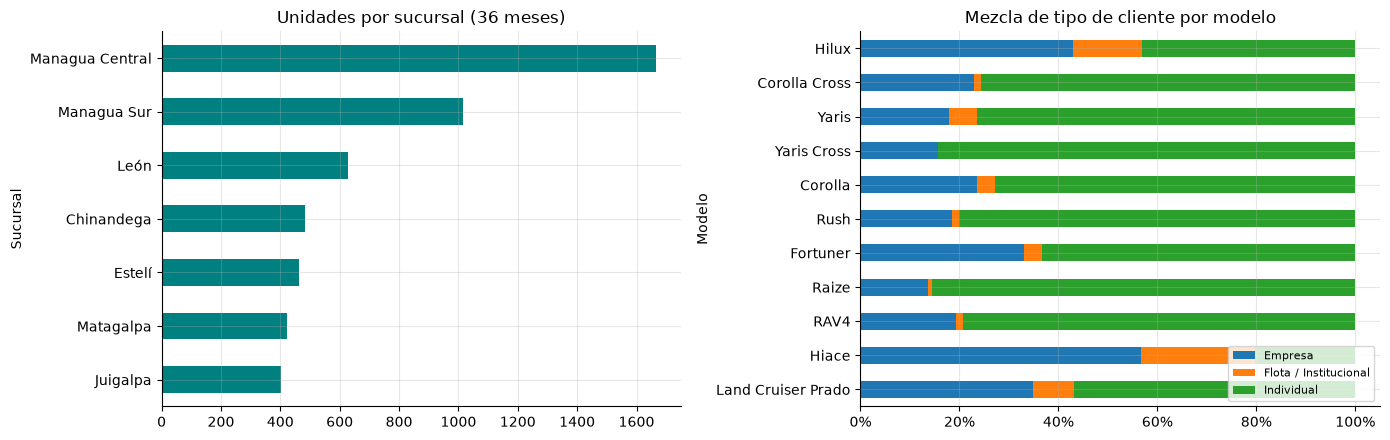

,Oct2023-Sep2024,Oct2024-Sep2025,Oct2025-Sep2026,Δ último año
Sucursal,,,,
Managua Central,587,554,526,-5.1%
Managua Sur,370,356,291,-18.3%
León,182,243,202,-16.9%
Chinandega,181,154,147,-4.5%
Estelí,166,151,147,-2.6%
Matagalpa,130,153,139,-9.2%
Juigalpa,154,122,125,+2.5%


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
base.groupby("Sucursal")["Unidades"].sum().sort_values().plot(
    kind="barh", ax=axes[0], color="teal", title="Unidades por sucursal (36 meses)"
)
pd.crosstab(
    base["Modelo"], base["Tipo de cliente"], values=base["Unidades"], aggfunc="sum", normalize="index"
).loc[tot_modelo.index[::-1]].plot(
    kind="barh", stacked=True, ax=axes[1], title="Mezcla de tipo de cliente por modelo"
)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

suc_año = base.pivot_table(index="Sucursal", columns="fiscal_year", values="Unidades", aggfunc="sum")
suc_año.columns = [f"Oct{a - 1}-Sep{a}" for a in suc_año.columns]
suc_año["Δ último año"] = suc_año.iloc[:, -1] / suc_año.iloc[:, -2] - 1
suc_año.sort_values(suc_año.columns[-2], ascending=False).style.format(
    {"Δ último año": "{:+.1%}"}, precision=0
)

- **Managua concentra la venta.** En el último año, Managua Sur (−65 unidades, −18 %) y León (−41, −17 %) explican **cerca de dos tercios** de la caída total (−156). León venía de subir mucho el año anterior (182 → 243), así que parte de su caída es una vuelta a su nivel habitual. Juigalpa es la única sucursal que crece.
- **Tipo de cliente:** Raize y RAV4 se venden casi solo a personas (venta de piso, que depende de tener la unidad en patio); Hiace, Land Cruiser Prado y Fortuner tienen más peso de empresas y flotas, una venta más "a pedido".
- El pedido a fábrica es nacional, así que el detalle por sucursal sirve para repartir las unidades cuando lleguen, no para decidir cuántas pedir.

### 4.5 Versión y color

In [10]:
u12 = base[base["Fecha"] > CORTE - pd.DateOffset(months=12)]
mix_ver = (
    u12.groupby(["Modelo", "Versión"])["Unidades"].sum() / u12.groupby("Modelo")["Unidades"].sum()
).rename("mix")
mix_ver = mix_ver.reset_index().sort_values(["Modelo", "mix"], ascending=[True, False])
mix_ver["acumulado"] = mix_ver.groupby("Modelo")["mix"].cumsum()
display(mix_ver.style.format({"mix": "{:.0%}", "acumulado": "{:.0%}"}).hide(axis="index"))
top_col = u12.groupby("Color")["Unidades"].sum().sort_values(ascending=False)
(top_col / top_col.sum()).to_frame("Mix de color (12m)").T.style.format("{:.1%}")

Modelo,Versión,mix,acumulado
Corolla,XLI 1.8 CVT,45%,45%
Corolla,GLI 2.0 CVT,29%,73%
Corolla,SEG Híbrido,27%,100%
Corolla Cross,XLI 2.0 CVT,35%,35%
Corolla Cross,SEG 2.0 CVT,34%,69%
Corolla Cross,SEG Híbrido,31%,100%
Fortuner,4x4 AT,41%,41%
Fortuner,4x2 AT,34%,75%
Fortuner,GR-S 4x4 AT,25%,100%
Hiace,Commuter 15 pasajeros,51%,51%


Color,Plata Metálico,Gris Grafito,Negro,Blanco,Blanco Perlado,Rojo,Azul Oscuro,Bronce
Mix de color (12m),19.5%,18.8%,16.3%,10.5%,10.3%,9.1%,8.3%,7.1%


Dos o tres versiones concentran el 80 % de la venta de cada modelo y ningún color pasa del 20 %.

### 4.6 Precio facturado vs precio de lista
¿La hoja *Economía* refleja lo que se factura? (sin notas de crédito ni líneas en córdobas)

In [11]:
pv = base[~base["is_credit_note"]].dropna(subset=["price_usd"])
precio = (pv["price_usd"] * pv["Unidades"]).groupby(pv["Modelo"]).sum() / pv.groupby("Modelo")[
    "Unidades"
].sum()
cmp = d.economics[["Precio promedio (USD)"]].join(precio.rename("Precio facturado prom."))
cmp["Δ vs lista"] = cmp["Precio facturado prom."] / cmp["Precio promedio (USD)"] - 1
cmp.style.format(
    {"Precio promedio (USD)": "{:,.0f}", "Precio facturado prom.": "{:,.0f}", "Δ vs lista": "{:+.1%}"}
)

,Precio promedio (USD),Precio facturado prom.,Δ vs lista
Modelo,,,
Hilux,"43,700","42,569",-2.6%
Fortuner,"55,540","54,868",-1.2%
Corolla,"27,210","26,562",-2.4%
Corolla Cross,"33,090","32,598",-1.5%
Yaris,"21,180","20,630",-2.6%
Yaris Cross,"27,650","27,330",-1.2%
RAV4,"42,690","42,221",-1.1%
Land Cruiser Prado,"78,920","76,123",-3.5%
Rush,"25,800","25,223",-2.2%


Sí: el precio facturado está a pocos puntos del de lista, así que *Economía* sirve para valorar el pedido.

## 5. Inventario
La hoja solo trae combinaciones con existencia; un modelo-mes ausente es stock cero.

### 5.1 Nivel de inventario vs ventas

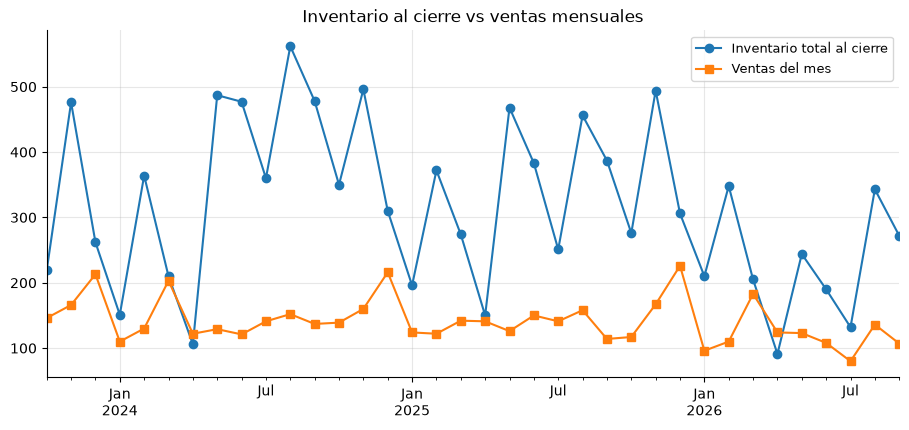

Rotación promedio (stock al cierre / venta del mes): 2.3 meses


In [12]:
inv = d.inventory.copy()
stock = monthly_table(inv, "Modelo", "Unidades", MODELOS)

fig, ax = plt.subplots()
stock.sum(axis=1).plot(ax=ax, marker="o", label="Inventario total al cierre")
mensual.reindex(stock.index).plot(ax=ax, marker="s", label="Ventas del mes")
ax.set_title("Inventario al cierre vs ventas mensuales")
ax.legend()
plt.show()
print(
    f"Rotación promedio (stock al cierre / venta del mes): {(stock.sum(axis=1) / mensual.reindex(stock.index)).mean():.1f} meses"
)

Diente de sierra trimestral: sube con cada llegada y baja hasta ~1 mes de venta antes de la siguiente.

### 5.2 Situación al corte (30-sep-2026)

In [13]:
inv_corte = inv[inv["month"] == ULT_MES].copy()
col_edad = "age_days"  # antigüedad con los 40 nulos ya imputados en 00_limpieza (S1.5 · ver 00_limpieza §3)
edad = (inv_corte[col_edad] * inv_corte["Unidades"]).groupby(inv_corte["Modelo"]).sum() / inv_corte.groupby(
    "Modelo"
)["Unidades"].sum()
transito = d.orders[d.orders["Estado"] == "En tránsito"].groupby("Modelo")["Unidades"].sum()
quiebres_6m = (stock.loc[MESES_6] == 0).sum()

situacion = (
    pd.DataFrame(
        {
            "Stock 30-sep-26": stock.loc[str(ULT_MES)],
            "Edad prom. (días)": edad,
            "En tránsito": transito,
            "Venta prom. 6m": ult6 / 6,
            "Venta prom. 12m": ult12 / 12,
            "Quiebres últimos 6m": quiebres_6m,
            "Quiebres 36m": (stock == 0).sum(),
        }
    )
    .reindex(MODELOS)
    .fillna({"Stock 30-sep-26": 0, "En tránsito": 0})
)
situacion["Cobertura stock (meses, 6m)"] = situacion["Stock 30-sep-26"] / situacion["Venta prom. 6m"]
situacion["Cobertura stock+tránsito (meses, 12m)"] = (
    situacion["Stock 30-sep-26"] + situacion["En tránsito"]
) / situacion["Venta prom. 12m"]
situacion.sort_values("Cobertura stock (meses, 6m)").style.format(precision=1).background_gradient(
    subset=["Cobertura stock (meses, 6m)", "Cobertura stock+tránsito (meses, 12m)"],
    cmap="RdYlGn",
    vmin=0,
    vmax=8,
)

,Stock 30-sep-26,Edad prom. (días),En tránsito,Venta prom. 6m,Venta prom. 12m,Quiebres últimos 6m,Quiebres 36m,"Cobertura stock (meses, 6m)","Cobertura stock+tránsito (meses, 12m)"
Modelo,,,,,,,,,
Corolla Cross,0,nan,30,8.7,17.8,5,7,0.0,1.7
Yaris Cross,0,nan,24,8.0,12.9,4,6,0.0,1.9
Rush,0,nan,12,3.3,7.3,5,6,0.0,1.6
RAV4,9,56.9,47,10.0,9.4,1,2,0.9,5.9
Land Cruiser Prado,4,63.0,12,3.8,3.4,0,0,1.0,4.7
Raize,20,94.7,24,9.7,8.7,0,0,2.1,5.1
Fortuner,20,52.5,20,7.8,8.8,1,1,2.6,4.6
Corolla,23,221.3,19,8.2,8.4,0,0,2.8,5.0
Yaris,41,85.1,64,13.8,14.1,0,0,3.0,7.5


- **Tres modelos en cero:** Corolla Cross, Yaris Cross y Rush.
- **Hilux:** ~4 meses de stock y 103 en tránsito, pero desbalanceado: Cabina Sencilla 4x4 MT con ~10 meses de cobertura y SRV 4x4 AT con ~1.3.
- **Corolla:** inventario de 190–300 días.

Para modelos con quiebres, la cobertura con base de 12 meses es más confiable que la de 6.

### 5.3 Meses en quiebre por modelo

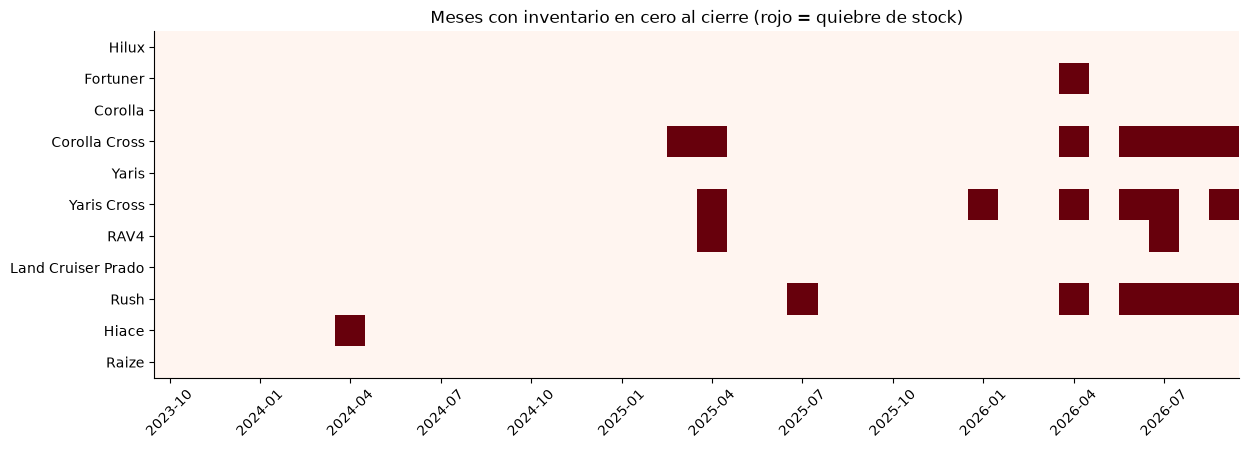

In [14]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.imshow((stock.T == 0).astype(int), aspect="auto", cmap="Reds", vmin=0, vmax=1)
ax.set_yticks(range(len(stock.columns)))
ax.set_yticklabels(stock.columns)
ax.set_xticks(range(0, len(stock.index), 3))
ax.set_xticklabels([str(p) for p in stock.index[::3]], rotation=45)
ax.set_title("Meses con inventario en cero al cierre (rojo = quiebre de stock)")
ax.grid(False)
plt.show()

### 5.4 Inventario envejecido
Unidades por tramo de antigüedad (desde 180 días aplica descuento).

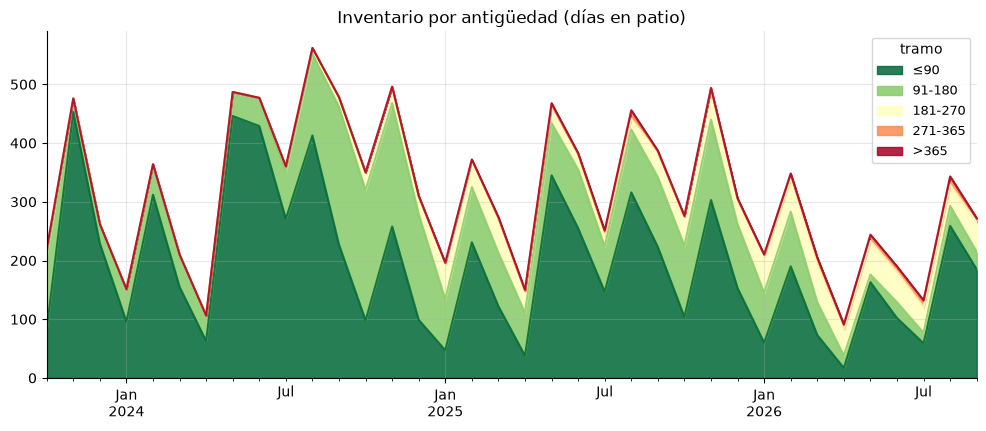

Combinaciones con más de 180 días al corte: 7 (57 unidades)
Unidades en tránsito de esas mismas versiones: {'Corolla SEG Híbrido': 5, 'Hilux Cabina Sencilla 4x4 MT': 21, 'Yaris Hatchback S AT': 18}


,Modelo,Versión,Color,Unidades,Antigüedad (días)
4015,Corolla,SEG Híbrido,Plata Metálico,7,302.00
4016,Corolla,SEG Híbrido,Gris Grafito,6,268.00
3982,Hilux,Cabina Sencilla 4x4 MT,Bronce,12,262.00
4032,Yaris,Hatchback S AT,Rojo,6,225.00
3983,Hilux,Cabina Sencilla 4x4 MT,Azul Oscuro,10,212.00
3981,Hilux,Cabina Sencilla 4x4 MT,Rojo,12,201.00
4018,Corolla,SEG Híbrido,Rojo,4,191.00


In [15]:
inv["tramo"] = pd.cut(
    inv[col_edad], [0, 90, 180, 270, 365, 9999], labels=["≤90", "91-180", "181-270", "271-365", ">365"]
)
envej = inv.pivot_table(
    index="month", columns="tramo", values="Unidades", aggfunc="sum", observed=False
).fillna(0)
ax = envej.plot(kind="area", stacked=True, figsize=(12, 4.5), cmap="RdYlGn_r", alpha=0.85)
ax.set_title("Inventario por antigüedad (días en patio)")
ax.set_xlabel("")
plt.show()

viejo = inv_corte[inv_corte[col_edad] > 180].sort_values(col_edad, ascending=False)
print(f"Combinaciones con más de 180 días al corte: {len(viejo)} ({viejo['Unidades'].sum():.0f} unidades)")
en_transito_viejo = (
    d.orders[d.orders["Estado"] == "En tránsito"]
    .groupby(["Modelo", "Versión"])["Unidades"]
    .sum()
    .reindex(viejo.set_index(["Modelo", "Versión"]).index.unique())
    .dropna()
)
print(
    "Unidades en tránsito de esas mismas versiones:",
    {f"{m} {v}": int(u) for (m, v), u in en_transito_viejo.items()},
)
viejo[["Modelo", "Versión", "Color", "Unidades", col_edad]].rename(columns={col_edad: "Antigüedad (días)"})

El inventario viejo se concentra en **Corolla SEG Híbrido** (17 unidades) y **Hilux Cabina Sencilla 4x4 MT** (34 con más de 180 días), y aún vienen más en tránsito. Esas versiones no deberían pedirse hasta liquidarlas.

## 6. Leads: demanda no atendida

Oportunidades: 12070 | Resultado: {'Perdida': 7563, 'Ganada': 4507}


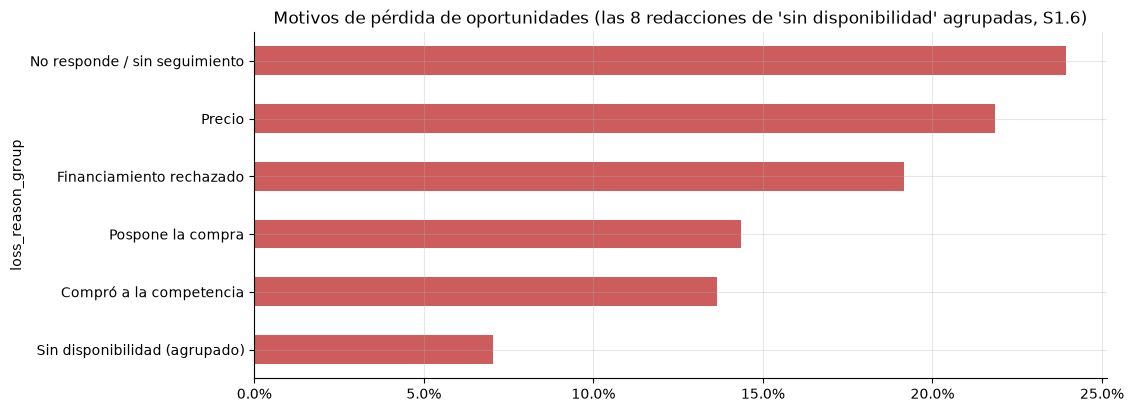

In [16]:
leads = d.leads[
    ~d.leads["special_fleet"]
]  # mismo criterio que en Ventas: las 2 flotas especiales fuera (S1.3 · ver 00_limpieza §3)
print(f"Oportunidades: {len(leads)} | Resultado: {leads['Resultado'].value_counts().to_dict()}")
g = leads[leads["Resultado"] == "Perdida"]["loss_reason_group"].value_counts(normalize=True)
ax = g.sort_values().plot(kind="barh", color="indianred")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title(
    "Motivos de pérdida de oportunidades (las 8 redacciones de 'sin disponibilidad' agrupadas, S1.6)"
)
plt.show()

### 6.1 Conversión y pérdidas por disponibilidad, por modelo
Unidades cotizadas y perdidas según el CRM (sin flotas especiales).

In [17]:
conv = leads.groupby("Modelo de interés").agg(
    leads=("ID Oportunidad", "size"),
    unidades_cotizadas=("Unidades", "sum"),
    tasa_ganada=("Resultado", lambda s: (s == "Ganada").mean()),
    perdidas_sin_disp=("no_availability", "sum"),
)
conv["% leads perdidos por disponibilidad"] = conv["perdidas_sin_disp"] / conv["leads"]
conv.reindex(MODELOS).sort_values("% leads perdidos por disponibilidad", ascending=False).style.format(
    {"tasa_ganada": "{:.1%}", "% leads perdidos por disponibilidad": "{:.1%}"}
).background_gradient(subset=["% leads perdidos por disponibilidad"], cmap="Reds")

,leads,unidades_cotizadas,tasa_ganada,perdidas_sin_disp,% leads perdidos por disponibilidad
Modelo de interés,,,,,
Hiace,431,515,36.2%,28,6.5%
Land Cruiser Prado,316,331,35.8%,19,6.0%
Corolla Cross,2204,2257,35.8%,123,5.6%
Rush,896,917,38.3%,49,5.5%
Raize,744,750,36.7%,39,5.2%
Yaris Cross,1268,1283,36.7%,59,4.7%
Corolla,899,924,36.3%,40,4.4%
Hilux,2747,2991,38.1%,105,3.8%
RAV4,546,555,37.4%,17,3.1%


### 6.2 ¿Las pérdidas por disponibilidad coinciden con los quiebres?
Si se pierde con el modelo en cero, falta volumen; si se pierde con stock, falta la versión o el color.

In [18]:
perd_disp = monthly_table(
    leads[leads["no_availability"]], "Modelo de interés", "Unidades", months=stock.index
)
x = pd.DataFrame(
    {"stock_inicio": stock.shift(1).stack(), "stock_fin": stock.stack(), "perdidas_disp": perd_disp.stack()}
).dropna()
x["situación del modelo en el mes"] = np.select(
    [x["stock_inicio"] == 0, x["stock_fin"] == 0],
    ["Empezó sin stock", "Se agotó durante el mes"],
    "Con stock todo el mes",
)
print("Unidades perdidas por disponibilidad según la situación de stock del modelo (36 meses):")
resumen_x = x.groupby("situación del modelo en el mes")["perdidas_disp"].agg(
    ["sum", "mean", "median", "size"]
)
resumen_x["% de las pérdidas"] = resumen_x["sum"] / resumen_x["sum"].sum()
display(resumen_x.style.format({"mean": "{:.2f}", "median": "{:.1f}", "% de las pérdidas": "{:.0%}"}))

x12 = x.loc[MESES_12]
print(
    f"Últimos 12 meses: {x12['perdidas_disp'].sum():.0f} unidades perdidas, de las cuales "
    f"{x12.loc[x12['situación del modelo en el mes'] == 'Con stock todo el mes', 'perdidas_disp'].sum():.0f} con el modelo en stock todo el mes."
)

ult12_perd = perd_disp.loc[MESES_12].sum()
tabla_perd = pd.DataFrame(
    {"Perdidas disp. 12m": ult12_perd, "Venta 12m": ult12, "% sobre venta": ult12_perd / ult12}
).sort_values("Perdidas disp. 12m", ascending=False)
print(
    f"Total 12 meses: {ult12_perd.sum():.0f} unidades perdidas = {ult12_perd.sum() / ult12.sum():.0%} de la venta del mismo periodo"
)
tabla_perd.style.format({"% sobre venta": "{:.1%}", "Perdidas disp. 12m": "{:.0f}", "Venta 12m": "{:.0f}"})

Unidades perdidas por disponibilidad según la situación de stock del modelo (36 meses):


,sum,mean,median,size,% de las pérdidas
situación del modelo en el mes,,,,,
Con stock todo el mes,450,1.29,0.0,350,70%
Empezó sin stock,103,5.15,1.0,20,16%
Se agotó durante el mes,86,5.73,4.0,15,13%


Últimos 12 meses: 315 unidades perdidas, de las cuales 180 con el modelo en stock todo el mes.


Total 12 meses: 315 unidades perdidas = 20% de la venta del mismo periodo


,Perdidas disp. 12m,Venta 12m,% sobre venta
Corolla Cross,74,213,34.7%
Hilux,67,414,16.2%
Yaris Cross,43,155,27.7%
Rush,34,88,38.6%
Hiace,24,74,32.4%
Corolla,23,101,22.8%
Yaris,23,169,13.6%
Raize,10,104,9.6%
Fortuner,9,105,8.6%
RAV4,5,113,4.4%


En 12 meses se perdieron **315 unidades** por disponibilidad (**20 % de la venta**), sobre todo en Corolla Cross, Hilux y Yaris Cross. Pero el **57 %** (70 % en 36 meses) ocurrió con el modelo en stock: es un problema de **mezcla**, no de volumen. Ejemplo: Hilux perdió 67 unidades sin bajar de 31 en patio, casi todas SRV 4x4 AT y Doble Cabina.

*Supuesto S1.7 (ver §1).*

### 6.3 Sustitución entre modelos

In [19]:
sust = leads.dropna(subset=["Modelo comprado (si difiere)"])
display(pd.crosstab(sust["Modelo de interés"], sust["Modelo comprado (si difiere)"]))
sv = leads.dropna(subset=["Versión comprada (si difiere)"])
ganadas = (leads["Resultado"] == "Ganada").sum()
print(
    f"Leads ganados con otro modelo: {len(sust)} ({len(sust) / ganadas:.1%} de las ganadas); "
    f"con otra versión del mismo modelo: {len(sv)} ({len(sv) / ganadas:.1%})"
)

# ¿La sustitución Corolla Cross → RAV4 ocurre cuando Corolla Cross no tiene stock?
cc_rav4 = sust[
    (sust["Modelo de interés"] == "Corolla Cross") & (sust["Modelo comprado (si difiere)"] == "RAV4")
]
cc_sin_stock = stock.shift(1)["Corolla Cross"].eq(0)
en_quiebre = cc_rav4["month"].map(cc_sin_stock).fillna(False)
cc_rav4_12m = cc_rav4[cc_rav4["Fecha cierre"] > CORTE - pd.DateOffset(months=12)]
print(
    f"Corolla Cross → RAV4: {len(cc_rav4)} casos; {int(en_quiebre.sum())} en los {int(cc_sin_stock.sum())} meses en que Corolla Cross empezó sin stock "
    f"({en_quiebre.sum() / cc_sin_stock.sum():.1f} por mes de quiebre frente a {(len(cc_rav4) - en_quiebre.sum()) / (~cc_sin_stock).sum():.1f} por mes con stock). "
    f"Últimos 12 meses: {len(cc_rav4_12m)} de las {int(ult12['RAV4'])} RAV4 vendidas ({int(ult12['RAV4']) - len(cc_rav4_12m)} de demanda propia, frente a {int(prev12['RAV4'])} el año anterior)."
)

Modelo comprado (si difiere),Corolla,Corolla Cross,Fortuner,Hilux,RAV4,Raize,Yaris
Modelo de interés,,,,,,,
Corolla,0,3,0,0,0,0,0
Corolla Cross,9,0,0,0,52,0,0
Fortuner,0,0,0,1,0,0,0
RAV4,0,1,0,0,0,0,0
Rush,0,0,2,0,0,12,0
Yaris Cross,0,1,0,0,0,7,4


Leads ganados con otro modelo: 92 (2.0% de las ganadas); con otra versión del mismo modelo: 395 (8.8%)
Corolla Cross → RAV4: 52 casos; 25 en los 6 meses en que Corolla Cross empezó sin stock (4.2 por mes de quiebre frente a 0.9 por mes con stock). Últimos 12 meses: 34 de las 113 RAV4 vendidas (79 de demanda propia, frente a 81 el año anterior).


La sustitución entre modelos es baja (2 % de las ganadas) pero tiene dirección: **Corolla Cross → RAV4** (52 casos) y **Rush → Raize** (12), sobre todo en meses de quiebre. Sin esos clientes, RAV4 vendió ~80–85 unidades, igual que el año anterior: su última ventana se dimensiona con esa demanda propia, no con 113.

## 7. Pedidos a fábrica

### 7.1 Lead time real

       lead_dias  eta_dias  retraso_vs_eta
count   2,076.00  2,076.00        2,076.00
mean      108.20    105.50            2.70
std        13.50      3.70           13.50
min        94.00     95.00           -9.00
25%       101.00    103.00           -4.00
50%       104.00    106.00           -1.00
75%       107.00    108.00            2.00
max       171.00    114.00           65.00

Unidades que llegaron en más de 130 días: 607 de 5101 (11.9%), en 99 de 134 pedidos; mediana 136 días. La ETA registrada de esas líneas era de 97–114 días: no anticipó el retraso.
Fracción de unidades tardías por trimestre de pedido: {Period('2023Q3', 'Q-DEC'): 0.0, Period('2023Q4', 'Q-DEC'): 0.15, Period('2024Q1', 'Q-DEC'): 0.2, Period('2024Q2', 'Q-DEC'): 0.15, Period('2024Q3', 'Q-DEC'): 0.11, Period('2024Q4', 'Q-DEC'): 0.15, Period('2025Q1', 'Q-DEC'): 0.08, Period('2025Q2', 'Q-DEC'): 0.11, Period('2025Q3', 'Q-DEC'): 0.09, Period('2025Q4', 'Q-DEC'): 0.12, Period('2026Q1', 'Q-DEC'): 0.15, Period('2026Q2',

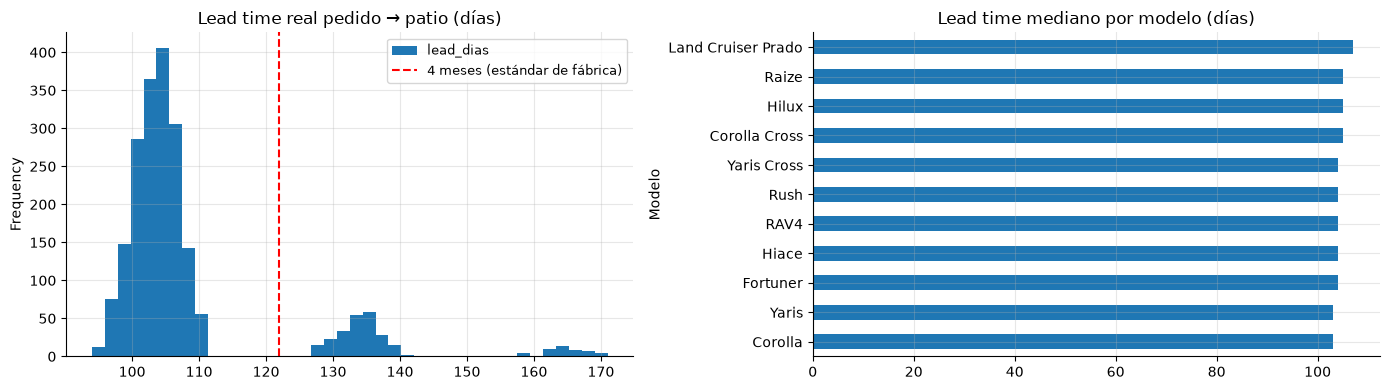

In [20]:
ped = d.orders
rec = ped[ped["Estado"] == "Recibido"].copy()
rec["lead_dias"] = (rec["Fecha de recepción"] - rec["Fecha pedido"]).dt.days
rec["eta_dias"] = (rec["Fecha estimada de llegada"] - rec["Fecha pedido"]).dt.days
rec["retraso_vs_eta"] = (rec["Fecha de recepción"] - rec["Fecha estimada de llegada"]).dt.days
print(rec[["lead_dias", "eta_dias", "retraso_vs_eta"]].describe().round(1).to_string())

# ¿La cola larga son casos aislados o una fracción estable de cada pedido?
tardias = rec[rec["lead_dias"] > 130]
por_q = (
    tardias.groupby(tardias["Fecha pedido"].dt.to_period("Q"))["Unidades"].sum()
    / rec.groupby(rec["Fecha pedido"].dt.to_period("Q"))["Unidades"].sum()
)
print(
    f"\nUnidades que llegaron en más de 130 días: {tardias['Unidades'].sum()} de {rec['Unidades'].sum()} "
    f"({tardias['Unidades'].sum() / rec['Unidades'].sum():.1%}), en {tardias['No. pedido'].nunique()} de {rec['No. pedido'].nunique()} pedidos; "
    f"mediana {tardias['lead_dias'].median():.0f} días. La ETA registrada de esas líneas era de {tardias['eta_dias'].min()}–{tardias['eta_dias'].max()} días: no anticipó el retraso."
)
print("Fracción de unidades tardías por trimestre de pedido:", por_q.fillna(0).round(2).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
rec["lead_dias"].plot(kind="hist", bins=40, ax=axes[0], title="Lead time real pedido → patio (días)")
axes[0].axvline(122, color="r", ls="--", label="4 meses (estándar de fábrica)")
axes[0].legend()
rec.groupby("Modelo")["lead_dias"].median().sort_values().plot(
    kind="barh", ax=axes[1], title="Lead time mediano por modelo (días)"
)
plt.tight_layout()
plt.show()

Lead time real de **~104 días (3.5 meses)**, estable; el "4 meses" del comunicado es conservador. Pero el **12 % de las unidades llega 1–2 meses tarde** en todos los trimestres y la ETA no lo anticipa.

### 7.2 Tránsito al corte

In [21]:
tr = ped[ped["Estado"] == "En tránsito"]
display(
    tr.pivot_table(
        index=tr["Fecha estimada de llegada"].dt.to_period("M"),
        columns="Modelo",
        values="Unidades",
        aggfunc="sum",
        fill_value=0,
    )
    .reindex(columns=MODELOS, fill_value=0)
    .assign(Total=lambda t: t.sum(axis=1))
    .rename_axis("Mes de llegada (ETA vigente)")
)
abril = tr[tr["Fecha pedido"].dt.month == 4]
dias_abril = (abril["Fecha estimada de llegada"] - abril["Fecha pedido"]).dt.days
print(
    f"Pedido de abril aún en tránsito: {abril['Unidades'].sum()} unidades ({abril.groupby('Modelo')['Unidades'].sum().to_dict()}), "
    f"ETA vigente {abril['Fecha estimada de llegada'].min():%d-%b}–{abril['Fecha estimada de llegada'].max():%d-%b-%Y}, "
    f"{dias_abril.min()}–{dias_abril.max()} días desde el pedido (ninguna ETA vencida al corte)."
)
largo = tr[(tr["Fecha estimada de llegada"] - tr["Fecha pedido"]).dt.days > 130]
print(
    f"Líneas con ETA a más de 130 días del pedido: {len(largo)}, {largo['Unidades'].sum()} unidades "
    f"({largo.groupby(largo['Fecha pedido'].dt.strftime('%b'))['Unidades'].sum().to_dict()})."
)
print(
    f"Total en tránsito: {tr['Unidades'].sum()} unidades; ETA máxima {tr['Fecha estimada de llegada'].max():%Y-%m-%d}."
)

Modelo,Hilux,Fortuner,Corolla,Corolla Cross,Yaris,Yaris Cross,RAV4,Land Cruiser Prado,Rush,Hiace,Raize,Total
Mes de llegada (ETA vigente),,,,,,,,,,,,
2026-10,19,0,1,0,0,0,3,0,0,0,0,23
2026-11,73,19,14,26,57,22,41,11,9,15,20,307
2026-12,7,1,3,4,7,2,3,1,3,0,3,34
2027-01,4,0,1,0,0,0,0,0,0,0,1,6


Pedido de abril aún en tránsito: 23 unidades ({'Corolla': 1, 'Hilux': 19, 'RAV4': 3}), ETA vigente 02-Oct–07-Oct-2026, 164–170 días desde el pedido (ninguna ETA vencida al corte).
Líneas con ETA a más de 130 días del pedido: 23, 59 unidades ({'Apr': 23, 'Jul': 36}).
Total en tránsito: 370 unidades; ETA máxima 2027-01-06.


Las **370 unidades en tránsito** llegan antes que el pedido de octubre (307 en noviembre), así que cuentan como posición disponible (**S1.8**: el tránsito con ETA anterior a la llegada del pedido suma a la posición). Para los modelos en cero cubren solo ~1.5 de los 4.4 meses del hueco.

### 7.3 Pedido frente a venta

,Pedido total 36m,Recibido 36m,Venta total 36m,Recibido / Venta,CV trimestral pedido,CV trimestral venta,Correlación pedido-venta
Modelo,,,,,,,
Corolla Cross,768,738,799,0.92,0.66,0.38,+0.20
Rush,332,320,346,0.92,0.61,0.39,+0.37
Yaris Cross,474,450,480,0.94,0.36,0.26,-0.15
Land Cruiser Prado,130,118,123,0.96,0.32,0.34,+0.42
Raize,330,306,313,0.98,0.34,0.28,+0.42
RAV4,316,269,275,0.98,0.46,0.28,+0.37
Corolla,378,359,365,0.98,0.37,0.22,-0.12
Fortuner,344,324,327,0.99,0.30,0.22,+0.56
Yaris,608,544,545,1.00,0.35,0.20,+0.25


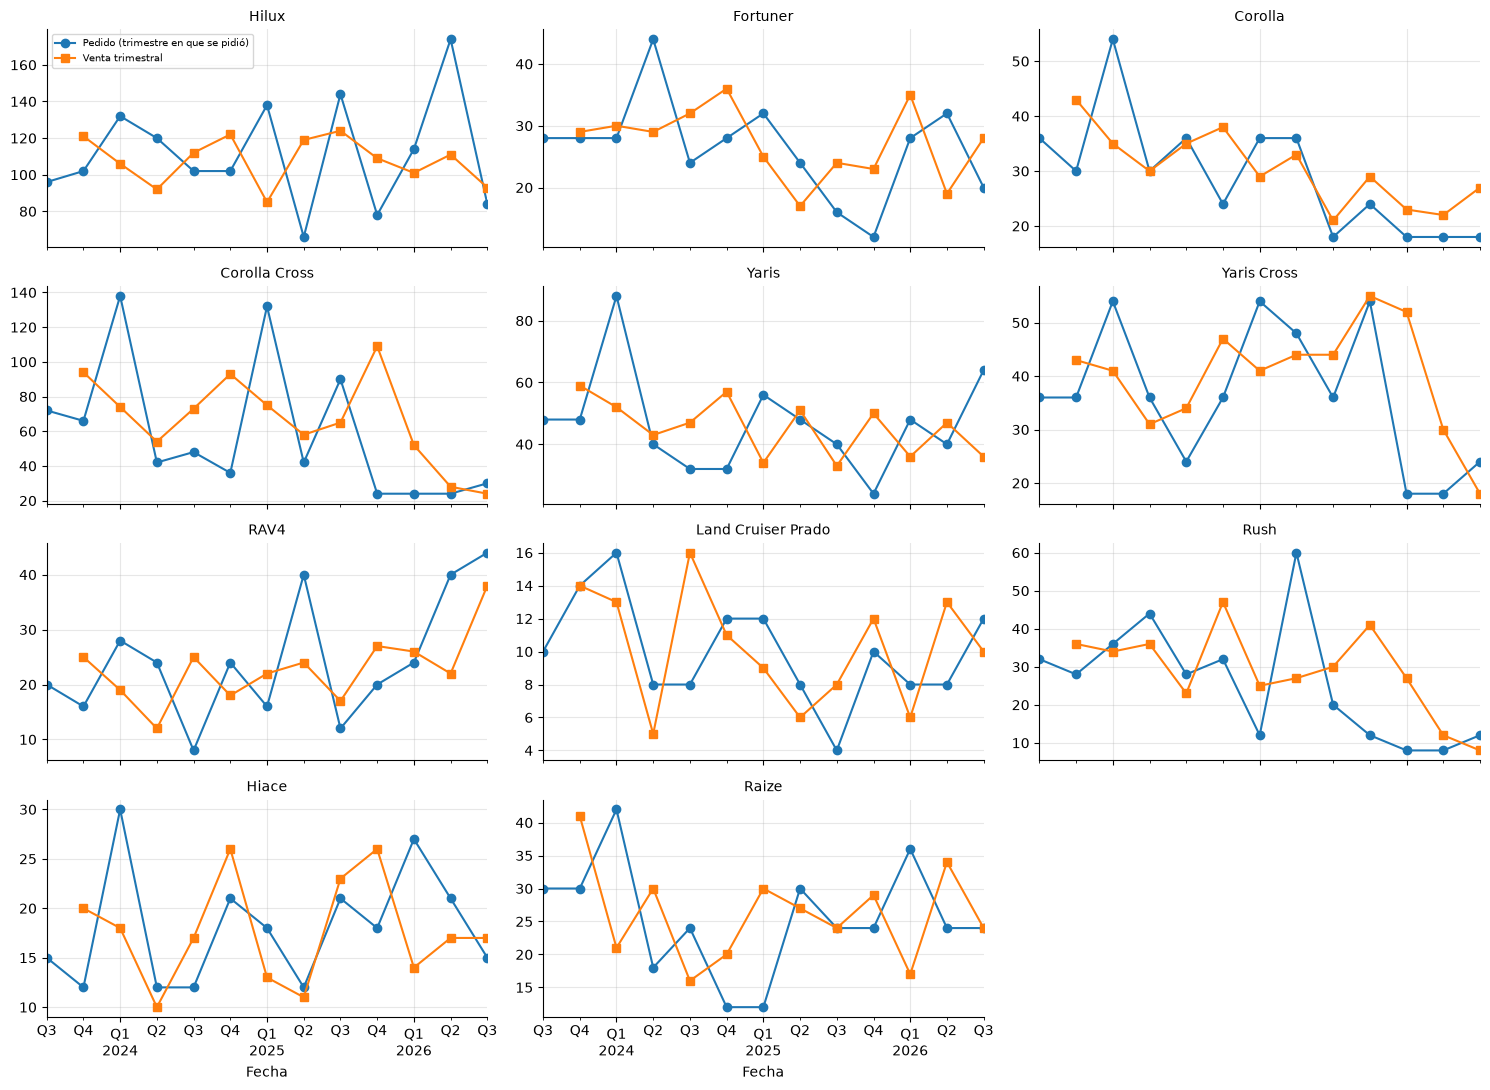

In [22]:
ped_inv = ped[ped["in_order_window"]]  # sin los dos pedidos especiales de flota
ped_q = ped_inv.pivot_table(
    index="order_quarter", columns="Modelo", values="Unidades", aggfunc="sum", fill_value=0
).reindex(columns=MODELOS, fill_value=0)
ven_q = (
    base.groupby([base["Fecha"].dt.to_period("Q"), "Modelo"])["Unidades"]
    .sum()
    .unstack()
    .reindex(columns=MODELOS, fill_value=0)
)
recibido = ped_inv[ped_inv["Estado"] == "Recibido"].groupby("Modelo")["Unidades"].sum()
comp = pd.DataFrame(
    {"Pedido total 36m": ped_q.sum(), "Recibido 36m": recibido, "Venta total 36m": ven_q.sum()}
)
comp["Recibido / Venta"] = comp["Recibido 36m"] / comp["Venta total 36m"]
comp["CV trimestral pedido"] = ped_q.std() / ped_q.mean()
comp["CV trimestral venta"] = ven_q.std() / ven_q.mean()
comp["Correlación pedido-venta"] = [ped_q[m].corr(ven_q[m].reindex(ped_q.index)) for m in MODELOS]
display(
    comp.sort_values("Recibido / Venta")
    .style.format(
        {
            "Recibido / Venta": "{:.2f}",
            "CV trimestral pedido": "{:.2f}",
            "CV trimestral venta": "{:.2f}",
            "Correlación pedido-venta": "{:+.2f}",
        },
        precision=0,
    )
    .background_gradient(subset=["Recibido / Venta"], cmap="RdYlGn_r", vmin=0.8, vmax=1.2)
)

fig, axes = plt.subplots(4, 3, figsize=(15, 11), sharex=True)
for ax, m in zip(axes.flat, MODELOS, strict=False):
    ped_q[m].plot(ax=ax, marker="o", label="Pedido (trimestre en que se pidió)")
    ven_q[m].plot(ax=ax, marker="s", label="Venta trimestral")
    ax.set_title(m, fontsize=10)
axes.flat[0].legend(fontsize=7)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

En 36 meses se recibió casi lo mismo que se vendió, pero el pedido trimestral **no sigue la venta**: ni la estacionalidad ni las caídas (Corolla Cross siguió recibiendo 24–30 por trimestre mientras su venta caía de 109 a 24). El sistema debe reaccionar a la demanda y a los quiebres.

## 8. Economía por modelo

In [23]:
e = d.economics.copy()
e["Margen por unidad (USD)"] = e["Precio promedio (USD)"] * e["Margen bruto %"]
e["Meses de plan piso que agotan el margen"] = (
    e["Margen por unidad (USD)"] / e["Costo financiero mensual por unidad (USD)"]
)
e["Costo 6m en patio + desc. 4% (USD)"] = (
    6 * e["Costo financiero mensual por unidad (USD)"] + 0.04 * e["Precio promedio (USD)"]
)
e["Margen tras 6m y desc. 4%"] = e["Margen por unidad (USD)"] - e["Costo 6m en patio + desc. 4% (USD)"]
e["Margen tras 9m y desc. 7%"] = e["Margen por unidad (USD)"] - (
    9 * e["Costo financiero mensual por unidad (USD)"] + 0.07 * e["Precio promedio (USD)"]
)
e["% del margen que queda (6m + 4%)"] = e["Margen tras 6m y desc. 4%"] / e["Margen por unidad (USD)"]
assert (
    (e["Costo unitario promedio (USD)"] * 0.009).round(0) == e["Costo financiero mensual por unidad (USD)"]
).all(), "plan piso ≠ 0.9 %"
e.drop(columns="Política de descuento por antigüedad").style.format(precision=0).format(
    {"Margen bruto %": "{:.0%}", "Meses de plan piso que agotan el margen": "{:.1f}"}
).format({"% del margen que queda (6m + 4%)": "{:+.0%}"}).background_gradient(
    subset=["Margen tras 6m y desc. 4%", "Margen tras 9m y desc. 7%"], cmap="RdYlGn"
)

,Precio promedio (USD),Margen bruto %,Costo unitario promedio (USD),Costo financiero mensual por unidad (USD),Margen por unidad (USD),Meses de plan piso que agotan el margen,Costo 6m en patio + desc. 4% (USD),Margen tras 6m y desc. 4%,Margen tras 9m y desc. 7%,% del margen que queda (6m + 4%)
Modelo,,,,,,,,,,
Hilux,43700,0.130000,38020,342,5681.000000,16.611111,3800.000000,1881.000000,-456.000000,+33%
Fortuner,55540,0.120000,48880,440,6664.800000,15.147273,4861.600000,1803.200000,-1183.000000,+27%
Corolla,27210,0.090000,24760,223,2448.900000,10.981614,2426.400000,22.500000,-1462.800000,+1%
Corolla Cross,33090,0.120000,29120,262,3970.800000,15.155725,2895.600000,1075.200000,-703.500000,+27%
Yaris,21180,0.070000,19690,177,1482.600000,8.376271,1909.200000,-426.600000,-1593.000000,-29%
Yaris Cross,27650,0.110000,24610,221,3041.500000,13.762443,2432.000000,609.500000,-883.000000,+20%
RAV4,42690,0.100000,38420,346,4269.000000,12.338150,3783.600000,485.400000,-1833.300000,+11%
Land Cruiser Prado,78920,0.110000,70240,632,8681.200000,13.736076,6948.800000,1732.400000,-2531.200000,+20%
Rush,25800,0.080000,23740,214,2064.000000,9.644860,2316.000000,-252.000000,-1668.000000,-12%


El costo financiero coincide con el 0.9 % mensual. Con seis meses en patio y el primer descuento, el margen queda **negativo en Yaris, Raize y Rush** y en cero en Corolla; Hilux y Fortuner conservan un tercio. Faltar cuesta el margen completo. Esta asimetría fija el stock de seguridad: generoso en Hilux y Fortuner, mínimo en Yaris, Raize, Rush y Corolla.

## 9. Hallazgos

1. **Datos usables:** 15 problemas tratados y las hojas cuadran entre sí.
2. **Demanda censurada:** la venta cae 9 %, pero 3 modelos terminan sin stock y se perdió el 20 % de la venta por disponibilidad.
3. **Mezcla, no volumen:** el 57 % de esas pérdidas ocurrió con el modelo en stock (Hilux pierde SRV y Doble Cabina mientras acumula Cabina Sencilla).
4. **Inventario desbalanceado:** ~7 meses de cobertura en Hilux y Yaris frente a menos de 2 en los modelos en quiebre.
5. **Lead time de 104 días**, con 12 % de llegadas tardías; todo el tránsito llega antes que el pedido.
6. **Estacionalidad:** pico en diciembre; el hueco pesa ~1.1x y el horizonte ~1.0x.
7. **RAV4:** demanda propia de ~80–85 al año; pedir solo lo que se venda hasta mayo de 2027.
8. **Economía asimétrica:** sobrar destruye margen en Yaris, Raize, Rush y Corolla; faltar es peor en Hilux y Fortuner.

**Qué se lleva el sistema de pedidos** ([`02_pedido_fabrica`](02_pedido_fabrica.ipynb))
1. Demanda base = venta neta sin flotas especiales.
2. Demanda ajustada con las pérdidas en meses de quiebre (S1.7); las pérdidas con stock van a la mezcla de versiones.
3. Posición al llegar = stock + tránsito − demanda del hueco (4.4 meses, factor ~1.1), nunca negativa.
4. Pedido para mediados de feb → mediados de may, más stock de seguridad según costos y llegada tardía, redondeado a las reglas de fábrica.
5. RAV4 sin stock de seguridad y con redondeo hacia abajo.

**Datos que se pedirían:** inventario por VIN, ETA original por línea, pedidos de flota de 2027, plan comercial 2027 y lanzamiento de la nueva RAV4.